# Week 5 Activity - Clustering Techniques
---

**Task**: Apply K-Means and Hierarchical Clustering to segment customer, Visualize results, compare methods, and derive insights.  

**Dataset**: `customer_segmentation.csv`

### 00. Setup:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn: Clusterting & Processing
from sklearn.preprocessing import StandardScaler # Z-score normalization
from sklearn.cluster import KMeans # K-Means algorithm
from sklearn.cluster import AgglomerativeClustering # Hierarchical clustering
from sklearn.metrics import silhouette_score

# sciPy: Hierarchical clustering dendogram
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

# Aesthetic defaults
sns.set_theme(style="whitegrid", palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)

## 1. Dataset preparation:
load the dataset, inspect its structure, and understand the variables

In [2]:
DATA_PATH = '../datasets/customer_segmentation.csv'

df = pd.read_csv(DATA_PATH)

print("=" * 60)
print("## dataset structure: ")
print("=" * 60)
print(f"shape: {df.shape[0]} rows x {df.shape[1]} columns")

print(f"\nColumn dtypes:")
print(df.dtypes)

print(f"\nDataset info:")
print(df.info)

print(f"\nMissing Values per column:")
print(df.isnull().sum())

## dataset structure: 
shape: 150 rows x 6 columns

Column dtypes:
CustomerID                      int64
Age                             int64
Annual_Spend                  float64
Membership_Duration             int64
Visits_Per_Month                int64
Preferred_Product_Category        str
dtype: object

Dataset info:
<bound method DataFrame.info of      CustomerID  Age  Annual_Spend  Membership_Duration  Visits_Per_Month  \
0          5001   37       5673.41                    5                 3   
1          5002   41      18648.46                   10                 2   
2          5003   30      15038.09                    4                 8   
3          5004   58      19781.78                    9                 3   
4          5005   59       6022.70                    6                 1   
..          ...  ...           ...                  ...               ...   
145        5146   64       8171.76                    1                 7   
146        5147   64       1

In [3]:
print("=" * 60)
print("## first 5 rows of the dataset: ")
print("=" * 60)

display(df.head())

print("=" * 60)
print("## Summary statistics: ")
print("=" * 60)
display(df.describe().round(2))

## first 5 rows of the dataset: 


,CustomerID,Age,Annual_Spend,Membership_Duration,Visits_Per_Month,Preferred_Product_Category
0,5001,37,5673.41,5,3,Electronics
1,5002,41,18648.46,10,2,Sports
2,5003,30,15038.09,4,8,Home & Garden
3,5004,58,19781.78,9,3,Clothing
4,5005,59,6022.70,6,1,Clothing


## Summary statistics: 


,CustomerID,Age,Annual_Spend,Membership_Duration,Visits_Per_Month
count,150.00,150.00,150.00,150.00,150.00
mean,5075.50,46.95,10110.08,7.17,6.01
std,43.45,17.08,5409.54,4.24,3.26
min,5001.00,19.00,1112.22,1.00,1.00
25%,5038.25,33.00,5792.63,3.25,3.00
50%,5075.50,44.50,8809.09,7.00,6.00
75%,5112.75,63.75,14696.75,11.00,9.00
max,5150.00,73.00,19818.11,14.00,11.00


## EDA - Visualization of the two Clustering features: 


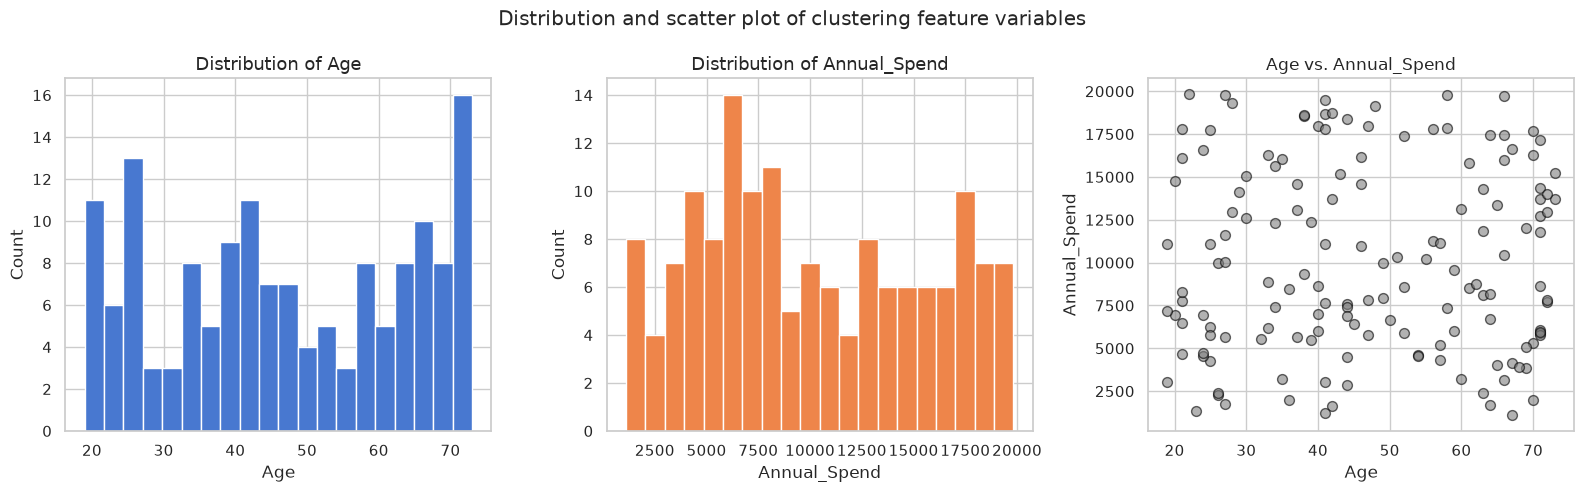

In [4]:
print("=" * 60)
print("## EDA - Visualization of the two Clustering features: ")
print("=" * 60)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

clustering_features = ["Age", "Annual_Spend"]
for i, col in enumerate(clustering_features):
    axes[i].hist(df[col], bins=20, edgecolor="white", color=sns.color_palette('muted')[i])
    axes[i].set_title(f'Distribution of {col}', fontsize=13)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')

axes[2].scatter(x=df[clustering_features[0]], y=df[clustering_features[1]], color='gray', edgecolor='black', alpha=0.6, s=50)
axes[2].set(
    title=f'{clustering_features[0]} vs. {clustering_features[1]}',
    xlabel=clustering_features[0],
    ylabel=clustering_features[1]
)


plt.suptitle("Distribution and scatter plot of clustering feature variables")
plt.tight_layout()
plt.show()

## 2. Data processing

### Normalizing clustering feature vars (Age, and Annual_Spend)

`Age` ranges 19-73  
`Annual_Spend` ranges roughly $1,100 - $19,800  

Clustering Algorithm group observations by measuring euclidean/geometric distance between points, which makes them sensitive to the scale of each variable.  
We're scaling using the the Z-score standardization using `StandardScaler`

In [5]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(df[clustering_features])

df_scaled=pd.DataFrame(
    data=scaled_data,
    columns=['Age_scaled', 'Annual_Spend_scaled']
)

print("=" * 60)
print("## Scaled data - summary stats:")
print("=" * 60)
df_scaled.describe().round(4)

## Scaled data - summary stats:


,Age_scaled,Annual_Spend_scaled
count,150.0000,150.0000
mean,0.0000,-0.0000
std,1.0034,1.0034
min,-1.6418,-1.6689
25%,-0.8193,-0.8008
50%,-0.1437,-0.2413
75%,0.9871,0.8507
max,1.5305,1.8006


## 3. K-Means Clustering:
How the algorithm work:
```
1. using number of clusters `k = 3`.
2. Randomly initialize k centroids
3. Repeat until convergence:  
    a. assign each point to the nearest centroid using the euclidean distance  
    b. update each centroid to the mean of its assigned points  
4. output: K clusters with final centroid positions.
```

In [6]:
kmeans = KMeans(
    n_clusters=3,
    random_state=123,
    n_init=10,
    max_iter=300
)

# fit the model and predict cluster labels
kmeans_labels = kmeans.fit_predict(X=scaled_data)

np.unique(kmeans_labels)

df["KMeans_Cluster"] = kmeans_labels + 1 # as clusters start at 0, make the start at 1

print("=" * 60)
print("## K-Means clustering results: ")
print("=" * 60)

print(f"\nCluster Sizes:")
print(df["KMeans_Cluster"].value_counts().sort_index())

print(f"\nwitin-Cluster sum of squares (WCSS): {kmeans.inertia_:.2f}")

print(f"\nCluster centroids (scaled):")
centroids_df = pd.DataFrame(
    data=kmeans.cluster_centers_,
    columns=["Age_scaled", "Annual_Spend_scaled"],
    index=[f"Cluster {i+1}" for i in range(3)]
)
print(centroids_df.round(3))

## K-Means clustering results: 

Cluster Sizes:
KMeans_Cluster
1    63
2    38
3    49
Name: count, dtype: int64

witin-Cluster sum of squares (WCSS): 106.09

Cluster centroids (scaled):
           Age_scaled  Annual_Spend_scaled
Cluster 1       0.992               -0.166
Cluster 2      -0.530                1.221
Cluster 3      -0.864               -0.733


In [7]:
# profiling clusters

print("=" * 60)
print("## K-Means Cluster profiles (original scale)")
print("=" * 60)

stats_funcs = ['mean', 'median', 'min', 'max', 'count']
cluster_profile = df.groupby('KMeans_Cluster')[clustering_features].agg(func=stats_funcs).round(2)
print(cluster_profile)

## K-Means Cluster profiles (original scale)
                  Age                      Annual_Spend                      \
                 mean median min max count         mean    median       min   
KMeans_Cluster                                                                
1               63.83   65.0  46  73    63      9215.07   8580.31   1112.22   
2               37.92   38.0  20  66    38     16692.64  17555.39  12340.12   
3               32.24   33.0  19  47    49      6155.95   6229.26   1253.67   

                                
                     max count  
KMeans_Cluster                  
1               17684.99    63  
2               19818.11    38  
3               11618.17    49  


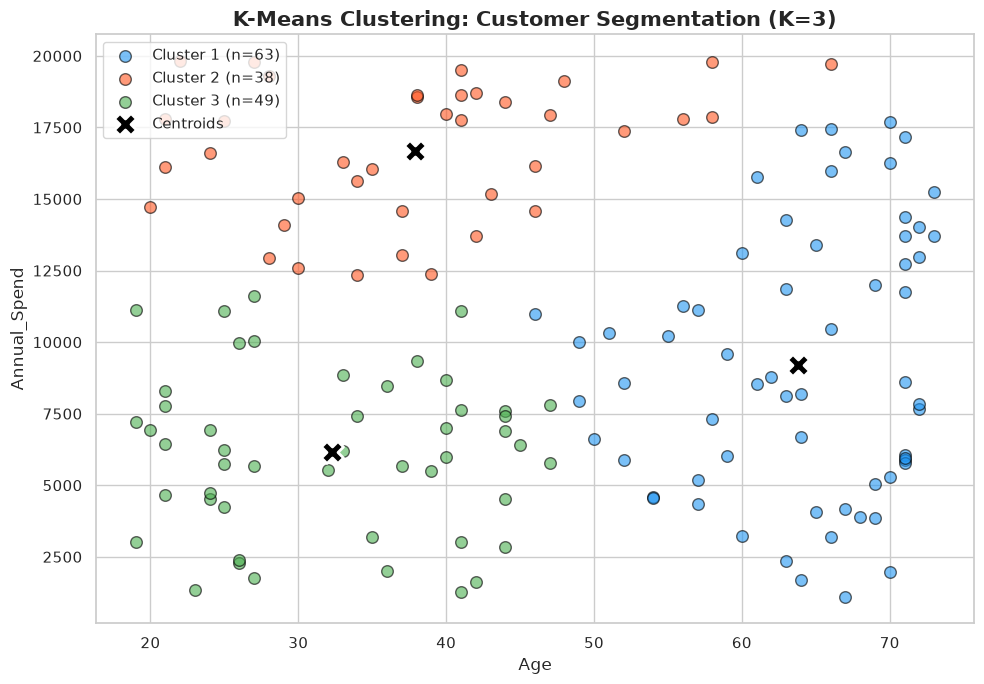

In [8]:
# Visualize K-Mean clusters

fig, ax = plt.subplots(figsize=(10, 7))

colors = ['#2196F3', '#FF5722', '#4CAF50']  # Blue, Orange, Green

for cluster_id in sorted(df['KMeans_Cluster'].unique()):
    row_selector_mask = df['KMeans_Cluster'] == cluster_id
    ax.scatter(
        x=df.loc[row_selector_mask, 'Age'],
        y=df.loc[row_selector_mask, 'Annual_Spend'],
        c=colors[cluster_id - 1],
        label=f'Cluster {cluster_id} (n={row_selector_mask.sum()})',
        alpha=0.6,
        edgecolors='black',
        s=70
    )

# Plot centriods
centroids_original_scale = scaler.inverse_transform(kmeans.cluster_centers_)
# display(centroids_original_scale)
ax.scatter(
    x=centroids_original_scale[:, 0],
    y=centroids_original_scale[:, 1],
    c='black', marker='X', s=250, linewidths=2,
    edgecolors='white', label='Centroids', zorder=5
)

ax.set_title('K-Means Clustering: Customer Segmentation (K=3)', fontsize=15, fontweight='bold')
ax.set_xlabel(clustering_features[0], fontsize=12)
ax.set_ylabel(clustering_features[1], fontsize=12)
ax.legend(loc='upper left')

plt.tight_layout()

finding optimal k using the elbow method:
1. run K-Means for K = 1, 2, 3, ..., 10
2. Record the Within-Cluster sum of squares (WCSS) for each K
3. plot WCSS vs K
4. the `elbow` where the curve bends suggests the optimal K 

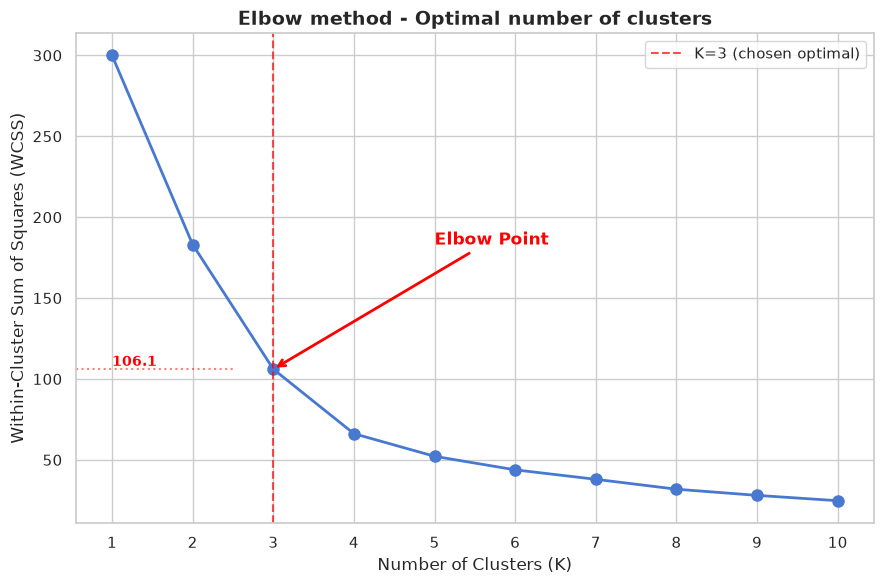

   K =  1  →  WCSS =   300.00
   K =  2  →  WCSS =   183.10
   K =  3  →  WCSS =   106.09 ◄── Chosen K
   K =  4  →  WCSS =    66.20
   K =  5  →  WCSS =    52.21
   K =  6  →  WCSS =    43.84
   K =  7  →  WCSS =    37.99
   K =  8  →  WCSS =    31.87
   K =  9  →  WCSS =    28.07
   K = 10  →  WCSS =    24.77


In [9]:
wcss_vals = []
k_range = range(1, 11)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=123, n_init=10)
    km.fit(scaled_data)
    wcss_vals.append(km.inertia_)

# plot the curve
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(k_range, wcss_vals, 'bo-', linewidth=2, markersize=8)
ax.axvline(x=3, color='red', linestyle='--', alpha=0.7, label='K=3 (chosen optimal)')
ax.set_title('Elbow method - Optimal number of clusters', fontsize=14, fontweight='bold')
ax.set_xlabel('Number of Clusters (K)', fontsize=12)
ax.set_ylabel('Within-Cluster Sum of Squares (WCSS)', fontsize=12)
ax.set_xticks(k_range)
ax.legend(fontsize=11)

# Horizontal line from elbow point to y-axis
ax.axhline(y=wcss_vals[2], color='red', linestyle=':', alpha=0.5, xmin=0, xmax=0.2)

# Annotate the elbow point
ax.annotate('Elbow Point', xy=(3, wcss_vals[2]), 
            xytext=(5, wcss_vals[1]), 
            arrowprops=dict(arrowstyle='->', color='red', lw=2),
            fontsize=12, color='red', fontweight='bold')

# Label the WCSS value on the y-axis
ax.annotate(f'{wcss_vals[2]:.1f}', xy=(1, wcss_vals[2]),
            fontsize=10, color='red', fontweight='bold',
            va='bottom', ha='left')

plt.tight_layout()
plt.show()

for k, wcss in zip(k_range, wcss_vals):
    marker = " ◄── Chosen K" if k == 3 else ""
    print(f"   K = {k:2d}  →  WCSS = {wcss:8.2f}{marker}")

## Hierarchical Clusterting:
how Hierarchical (agglomerative) clustering work:
```
1. Start with each data point as its own cluster (N clusters)
2. Repeat:
    a. Find the two closest clusters
    b. merge them into one cluster
3. Stop when 1 cluster remains
4. cut the dendogram at desired height to get K clusters
```

Linkage method used is complete linkage (which measures max. distance between clusters)

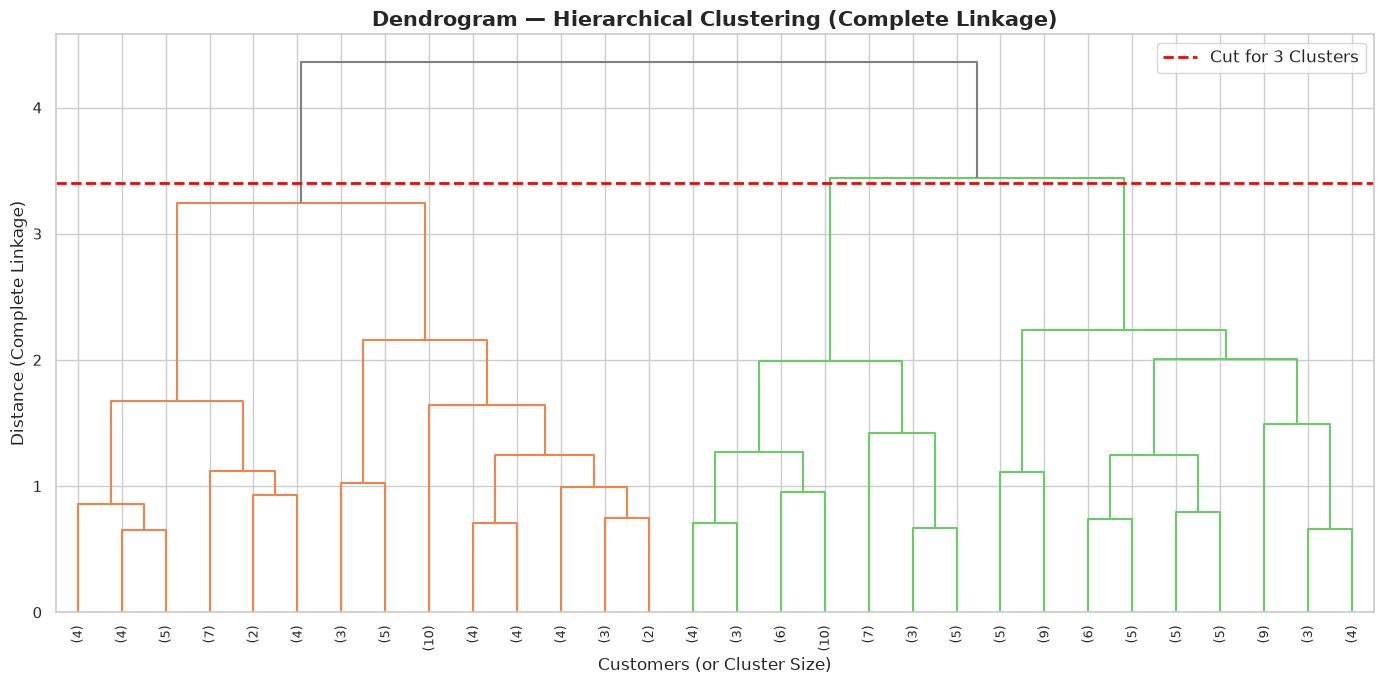

In [10]:
# Compute the linkage matrix using the complete method
linkage_matrix = linkage(y=scaled_data, method='complete', metric='euclidean')

# visualize the dendogram
fig, ax = plt.subplots(figsize=(14, 7))

# Create the dendrogram
dend = dendrogram(
    linkage_matrix,
    truncate_mode='lastp',    # Show only last p merged clusters
    p=30,                     # Show top 30 clusters for readability
    leaf_rotation=90,
    leaf_font_size=9,
    color_threshold=3.5,      # Color threshold for distinct branches
    above_threshold_color='gray',
    ax=ax
)

# Add a horizontal line showing where we cut for 3 clusters
ax.axhline(y=3.4, color='red', linestyle='--', linewidth=2,
           label='Cut for 3 Clusters')

ax.set_title('Dendrogram — Hierarchical Clustering (Complete Linkage)',
             fontsize=15, fontweight='bold')
ax.set_xlabel('Customers (or Cluster Size)', fontsize=12)
ax.set_ylabel('Distance (Complete Linkage)', fontsize=12)
ax.legend(fontsize=12)

plt.tight_layout()
plt.show()

In [11]:
# Cut Dendogram to form 3 clusters

# cut the tree at k = 3 clusters
hc_labels = fcluster(linkage_matrix, t=3, criterion='maxclust')

# add hierarchical cluster labels to the Dataframe
df['HC_Cluster']=hc_labels

print("=" * 60)
print("## Hierarchical clusterting result (K=3, Complete Linkage)")
print("=" * 60)
print(f"\nCluster Sizes:")
print(df['HC_Cluster'].value_counts().sort_index())

print("=" * 60)
print('## Hierarchical cluster profiles (original scale)')
print("=" * 60)
hc_profiles = df.groupby('HC_Cluster')[clustering_features].agg(func=stats_funcs).round(2)
print(hc_profiles)

## Hierarchical clusterting result (K=3, Complete Linkage)

Cluster Sizes:
HC_Cluster
1    61
2    38
3    51
Name: count, dtype: int64
## Hierarchical cluster profiles (original scale)
              Age                      Annual_Spend                      \
             mean median min max count         mean    median       min   
HC_Cluster                                                                
1           48.48   46.0  20  73    61     15802.70  16043.52  10992.39   
2           63.03   64.0  49  72    38      6356.03   5985.84   1112.22   
3           33.14   33.0  19  52    51      6098.39   6229.26   1253.67   

                            
                 max count  
HC_Cluster                  
1           19818.11    61  
2           11253.35    38  
3           11618.17    51  


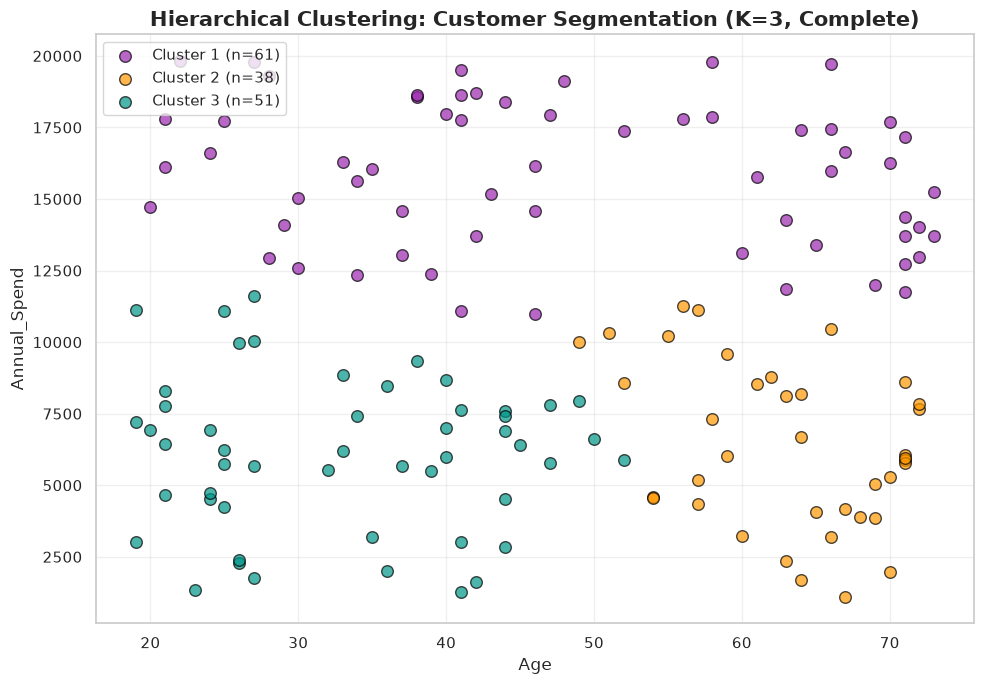

In [12]:
# visualize hierarchical clusters on a scatterplot
fig, ax = plt.subplots(figsize=(10, 7))

colors_hc = ['#9C27B0', '#FF9800', '#009688']  # Purple, Amber, Teal

for cluster_id in sorted(df['HC_Cluster'].unique()):
    mask = df['HC_Cluster'] == cluster_id
    ax.scatter(
        df.loc[mask, clustering_features[0]],
        df.loc[mask, clustering_features[1]],
        c=colors_hc[cluster_id - 1],
        label=f'Cluster {cluster_id} (n={mask.sum()})',
        alpha=0.7,
        edgecolors='black',
        s=70
    )

ax.set_title('Hierarchical Clustering: Customer Segmentation (K=3, Complete)',
             fontsize=15, fontweight='bold')
ax.set_xlabel(clustering_features[0], fontsize=12)
ax.set_ylabel(clustering_features[1], fontsize=12)
ax.legend(fontsize=11, loc='upper left')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Comparison and insights
comparing the results of k-means and hierarchical clustering
- similar or different?
- what insights can be drawn from customer segments?

In [13]:
print("=" * 60)
print('## Comparison: K-Means vs. Hierarchical Clustering')
print("=" * 60)

cross_tab = pd.crosstab(
    index=df['KMeans_Cluster'],
    columns=df['HC_Cluster'],
    rownames=['K-Means'],
    colnames=['Hierarchical']
)

print("\nCross tabulation of cluster assignments:")
print(cross_tab)

# calculate agreement percentage 
total = len(df)
max_matches = cross_tab.max(axis=1).sum()
agreement = (max_matches/total)
print(f"Approximate agreement between methods: {agreement: .2%}")

## Comparison: K-Means vs. Hierarchical Clustering

Cross tabulation of cluster assignments:
Hierarchical   1   2   3
K-Means                 
1             22  38   3
2             38   0   0
3              1   0  48
Approximate agreement between methods:  82.67%


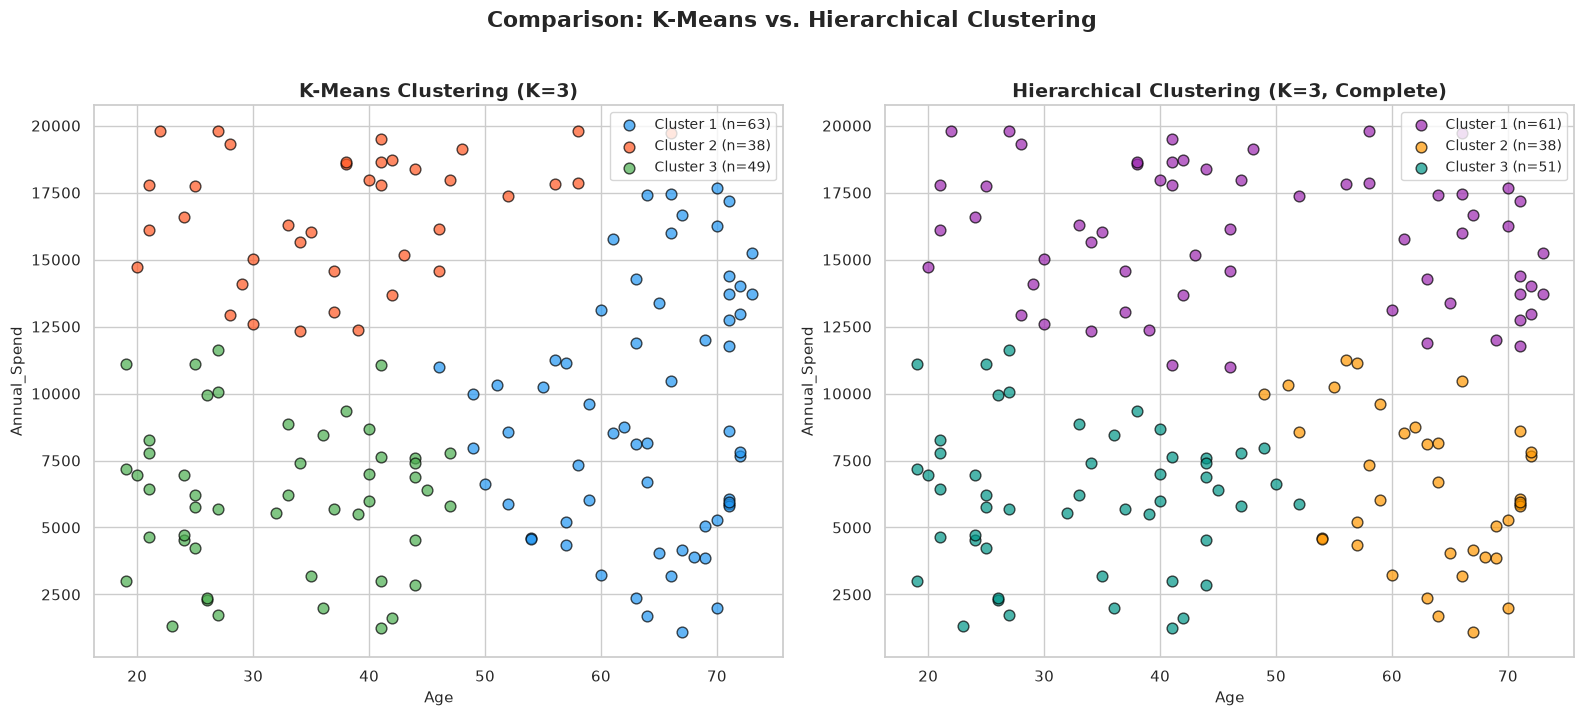

In [14]:
# Side-by-side visualization of both methods

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# K-Means plot
for cid in sorted(df['KMeans_Cluster'].unique()):
    mask = df['KMeans_Cluster'] == cid
    axes[0].scatter(
        df.loc[mask, 'Age'], df.loc[mask, 'Annual_Spend'],
        c=colors[cid - 1], label=f'Cluster {cid} (n={mask.sum()})',
        alpha=0.7, edgecolors='black', s=60
    )
axes[0].set_title('K-Means Clustering (K=3)', fontsize=14, fontweight='bold')
axes[0].set_xlabel(clustering_features[0], fontsize=11)
axes[0].set_ylabel(clustering_features[1], fontsize=11)
axes[0].legend(fontsize=10)

# Hierarchical plot
for cid in sorted(df['HC_Cluster'].unique()):
    mask = df['HC_Cluster'] == cid
    axes[1].scatter(
        df.loc[mask, 'Age'], df.loc[mask, 'Annual_Spend'],
        c=colors_hc[cid - 1], label=f'Cluster {cid} (n={mask.sum()})',
        alpha=0.7, edgecolors='black', s=60
    )
axes[1].set_title('Hierarchical Clustering (K=3, Complete)',
                  fontsize=14, fontweight='bold')
axes[1].set_xlabel(clustering_features[0], fontsize=11)
axes[1].set_ylabel(clustering_features[1], fontsize=11)
axes[1].legend(fontsize=10)

plt.suptitle('Comparison: K-Means vs. Hierarchical Clustering',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [15]:
# Cluster profiles 

print("=" * 70)
print("DETAILED K-MEANS CLUSTER PROFILES (All Variables)")
print("=" * 70)

numeric_cols = ['Age', 'Annual_Spend', 'Membership_Duration', 'Visits_Per_Month']
km_detailed = df.groupby('KMeans_Cluster')[numeric_cols].mean().round(2)
print(km_detailed)

print("\n" + "=" * 70)
print("PREFERRED PRODUCT CATEGORY DISTRIBUTION BY K-MEANS CLUSTER")
print("=" * 70)
product_dist = pd.crosstab(
    df['KMeans_Cluster'],
    df['Preferred_Product_Category'],
    normalize='index'
).round(3) * 100
print(product_dist)
print("\n(Values shown as percentages within each cluster)")

DETAILED K-MEANS CLUSTER PROFILES (All Variables)
                  Age  Annual_Spend  Membership_Duration  Visits_Per_Month
KMeans_Cluster                                                            
1               63.83       9215.07                 6.52              5.78
2               37.92      16692.64                 6.87              5.63
3               32.24       6155.95                 8.24              6.59

PREFERRED PRODUCT CATEGORY DISTRIBUTION BY K-MEANS CLUSTER
Preferred_Product_Category  Clothing  Electronics  Home & Garden  Sports
KMeans_Cluster                                                          
1                               30.2         22.2           23.8    23.8
2                               21.1         28.9           21.1    28.9
3                               14.3         36.7           26.5    22.4

(Values shown as percentages within each cluster)


In [16]:
# Display final dataset with cluster assignments

print("=" * 60)
print("FINAL DATASET WITH CLUSTER LABELS")
print("=" * 60)
df.head(15)

FINAL DATASET WITH CLUSTER LABELS


,CustomerID,Age,Annual_Spend,Membership_Duration,Visits_Per_Month,Preferred_Product_Category,KMeans_Cluster,HC_Cluster
0,5001,37,5673.41,5,3,Electronics,3,3
1,5002,41,18648.46,10,2,Sports,2,1
2,5003,30,15038.09,4,8,Home & Garden,2,1
3,5004,58,19781.78,9,3,Clothing,2,1
4,5005,59,6022.70,6,1,Clothing,1,2
5,5006,25,17737.00,7,1,Home & Garden,2,1
6,5007,56,11253.35,4,10,Electronics,1,2
7,5008,40,8662.06,6,11,Home & Garden,3,3
8,5009,19,11115.16,4,7,Electronics,3,3
9,5010,25,11088.69,9,7,Sports,3,3


---
## 10. Reflection

### How effective were the clustering algorithms in segmenting customers?

Both K-Means and Hierarchical Clustering were effective in segmenting the 150 customers into three meaningful groups based on Age and Annual Spend. The K-Means algorithm produced well-defined, compact clusters by iteratively minimizing the within-cluster sum of squares (WCSS). Hierarchical clustering, using the complete linkage method, produced a visually informative dendrogram that revealed the natural hierarchy of customer groupings. The cross-tabulation between the two methods showed substantial agreement at 82.7%, indicating both captured similar underlying patterns. Notice that the cluster name is arbitrary, cluster 1 in K-Means does not necessarily map to cluster 1 in the hierarchical clusters.

### What patterns or insights did you observe in the clusters?

The clustering analysis revealed distinct customer segments. Looking at the K-Means scatterplot, One cluster typically represents younger customers with low-to-moderate spending (Cluster 3), another captures older customers with varied spending patterns low to high(Cluster 1), and a third group shows a mix of ages with higher annual spending than the other 2, that's (Cluster 2). These segments align with common retail customer profiles, budget-conscious shoppers, high-value customers, and emerging spenders. Interestingly, examining additional variables such as Membership Duration and Visits Per Month across clusters provides deeper insight into engagement patterns, though these were not used as clustering features.

### Which algorithm would you recommend for this dataset, and why?

For this relatively small dataset (150 records), I would recommend **starting with Hierarchical Clustering for exploratory analysis** (the dendrogram helps visualize natural groupings without pre-specifying K) and then **using K-Means for the final segmentation** (it is more computationally efficient and produces tighter clusters). This two-step approach leverages the strengths of both methods: hierarchical clustering for discovery and K-Means for actionable segmentation. For larger datasets, K-Means alone would be preferable due to its O(n·K·t) scalability (linear time complexity in terms of input size) compared to hierarchical clustering's O(n²) memory requirements.